# Q4 — One-way ANOVA: Burnt Area per Fire across Municipalities (2018–2025)

**Project:** Human Influence on Wildfire Ignitions in Portugal: Before and After 2017  
**Group:** (names and student numbers)  **Section:** Q4 — One-way ANOVA

**Contents:** 01 Introduction · 02 Data preparation and validation · 03 Exploratory data analysis · 04 ANOVA assumptions · 05 Transformation and method selection · 06 One-way ANOVA · 07 Post-hoc comparisons · 08 Selected robustness checks · 09 Discussion and conclusion

---
## 01 — Introduction and Research Question

**Research question (Q4).** Does the mean log-transformed burnt area per fire differ significantly across Chaves, Montalegre, Ourém and Tomar during 2018–2025?

| Element | Definition |
|---|---|
| Unit of observation | One wildfire occurrence (one SGIF record) |
| Response variable | ln(`Total_Burnt_Area`): natural logarithm of the final burnt area in hectares |
| Factor | `Concelho` (municipality), 4 levels |
| Period | 2018–2025 (filtered with `Ano`; 2017 is excluded as a transition year) |
| Significance level | α = 0.05 |

**Hypotheses (on the log scale)**

- H₀: the population means of ln(burnt area) are equal in the four municipalities.
- H₁: at least one population mean of ln(burnt area) differs.

**What the ANOVA compares.** For strictly positive areas, the mean of ln(area) is the logarithm of the *geometric mean* of the area. Therefore, comparing means of ln(area) is equivalent to comparing geometric means (the "typical" fire) on the original scale, and differences become **ratios**. The ANOVA does **not** directly test equality of the *arithmetic* mean burnt area in hectares; the arithmetic means are reported only as descriptive statistics.

**Why the logarithm?** Burnt areas are extremely right-skewed (a few huge fires and many tiny ones). Sections 03–05 show that the classical ANOVA assumptions are not met on the original scale but are reasonably met on the log scale.

In [1]:
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

STUDY_YEARS = (2018, 2025)
MUNICIPALITIES = ["Chaves", "Montalegre", "Ourém", "Tomar"]    # fixed order for all tables and figures
Y = "Total_Burnt_Area"                                          # burnt area in hectares (original scale)
# No randomness is used anywhere in this notebook, so the results are fully deterministic.

# Look for the data folder in the current folder and up to 3 parent folders (relative paths only)
def find_data_dir(filename="wildfires_processed.xlsx"):
    here = Path.cwd().resolve()
    for base in [here, *list(here.parents)[:3]]:
        for sub in ["01_dataset/processed", "processed", "data", "."]:
            if (base / sub / filename).exists():
                return base / sub
    raise FileNotFoundError(f"Could not find {filename} (current folder: {here}). Put the notebook next to '01_dataset' or set DATA_DIR by hand.")

DATA_DIR = find_data_dir()
print("Data folder found:", "/".join(DATA_DIR.parts[-2:]))

# Plot style: one fixed colour per municipality (colour-blind-safe set), same order everywhere
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
COLORS = dict(zip(MUNICIPALITIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

def qq_panel(ax, resid, color, title, ylabel="Residual"):
    # Normal Q-Q plot with a reference line through the quartiles
    (osm, osr), _ = stats.probplot(resid, dist="norm")
    ax.scatter(osm, osr, s=5, color=color, alpha=.5, edgecolor="none")
    lo, hi = np.percentile(resid, [25, 75]); z_lo, z_hi = stats.norm.ppf([.25, .75])
    ax.plot(osm, np.median(resid) + (hi - lo) / (z_hi - z_lo) * osm, color="#0b0b0b", linewidth=1)
    ax.set_title(title); ax.set_xlabel("Theoretical quantiles"); ax.set_ylabel(ylabel)

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | matplotlib 3.11.2
Data folder found: 01_dataset/processed


## 02 — Data Preparation and Validation

The first version of `q4_burnt_area_municipality.xlsx` only removed missing values and **did not filter the years** (7,255 rows, 2011–2025). Even though the preprocessing notebook has since been corrected, we rebuild the Q4 sample here from the main processed file, filter by `Ano` and **reconcile** with the Q4 file, so that the notebook fails loudly if a wrong version is used. No original file is modified.

In [2]:
raw = pd.read_excel(DATA_DIR / "wildfires_processed.xlsx")
raw["Codigo_SGIF"] = raw["Codigo_SGIF"].astype(str)      # identifiers mix int and str in the Excel file
print("Processed file:", raw.shape)

# The Q4 file is only used to cross-check; if it is locked (open in Excel/OneDrive) we continue without it
try:
    q4_file = pd.read_excel(DATA_DIR / "q4_burnt_area_municipality.xlsx")
    q4_file["Codigo_SGIF"] = q4_file["Codigo_SGIF"].astype(str)
    print("Q4 file:", q4_file.shape, "| years", q4_file["Ano"].min(), "-", q4_file["Ano"].max())
except (PermissionError, FileNotFoundError) as err:
    q4_file = None
    print("Q4 file not readable, cross-check skipped:", type(err).__name__)

# Step-by-step construction of the Q4 sample, with an attrition log
steps = []
d = raw.copy();                                   steps.append(("Processed file (2011-2025, 4 municipalities)", len(d)))
d = d[d["Concelho"].isin(MUNICIPALITIES)];        steps.append(("Keep the 4 municipalities", len(d)))
d = d[d["Ano"].between(*STUDY_YEARS)];            steps.append(("Keep 2018-2025 (uses Ano, not the derived Period)", len(d)))
d = d.dropna(subset=[Y]);                         steps.append(("Drop missing burnt area", len(d)))
d = d[d[Y] >= 0];                                 steps.append(("Drop negative burnt area (invalid)", len(d)))

# Primary descriptive sample: ALL valid occurrences, whatever the cause. Nothing is dropped for cause or size.
q4 = d.reset_index(drop=True)
q4["Concelho"] = pd.Categorical(q4["Concelho"], categories=MUNICIPALITIES, ordered=True)

# Analytical sample for the ANOVA: ln() is only defined for positive areas
q4_ln = q4[q4[Y] > 0].copy()
q4_ln["ln_area"] = np.log(q4_ln[Y])
steps.append(("ANOVA sample: drop fires with 0 ha (ln undefined)", len(q4_ln)))

attrition = pd.DataFrame(steps, columns=["step", "n_remaining"])
attrition["removed"] = -attrition["n_remaining"].diff().fillna(0).astype(int)
print(attrition.to_string(index=False))

Processed file: (7255, 50)
Q4 file: (2739, 50) | years 2018 - 2025
                                             step  n_remaining  removed
     Processed file (2011-2025, 4 municipalities)         7255        0
                        Keep the 4 municipalities         7255        0
Keep 2018-2025 (uses Ano, not the derived Period)         2739     4516
                          Drop missing burnt area         2739        0
               Drop negative burnt area (invalid)         2739        0
ANOVA sample: drop fires with 0 ha (ln undefined)         2738        1


In [3]:
# Validation assertions
assert q4["Ano"].between(2018, 2025).all(),                      "years outside 2018-2025"
assert set(q4["Concelho"].astype(str)) == set(MUNICIPALITIES),   "missing municipality"
assert pd.api.types.is_numeric_dtype(q4[Y]) and q4[Y].notna().all() and (q4[Y] >= 0).all()
assert q4["Codigo_SGIF"].is_unique,                              "duplicated SGIF identifiers"
assert (q4[Y] == q4["AreaTotal_ha"]).all(),                      "Total_Burnt_Area differs from AreaTotal_ha"
assert (q4["Period"] == "Post-2017").all(),                      "Period label inconsistent with Ano"
assert len(q4) == 2739 and len(q4_ln) == 2738 and np.isfinite(q4_ln["ln_area"]).all()
assert q4["Concelho"].value_counts().to_dict() == {"Montalegre": 1146, "Ourém": 620, "Chaves": 555, "Tomar": 418}

if q4_file is not None:   # reconcile with the (corrected) Q4 file
    in_window = q4_file[q4_file["Ano"].between(*STUDY_YEARS)]
    assert set(in_window["Codigo_SGIF"]) == set(q4["Codigo_SGIF"]), "does not reconcile with the Q4 file"
    print("Q4 file already restricted to 2018-2025:", bool(q4_file["Ano"].between(*STUDY_YEARS).all()))
print("All validation checks passed. n =", len(q4), "| ANOVA sample n =", len(q4_ln))

# Quality-control summary
g_ = q4.groupby("Concelho", observed=True)
qc = pd.DataFrame({"n": g_.size(), "area = 0 ha": g_[Y].apply(lambda s: int((s == 0).sum())),
                   "% < 1 ha": g_[Y].apply(lambda s: round(100 * (s < 1).mean(), 1)),
                   "missing cause": g_["TipoCausa"].apply(lambda s: int(s.isna().sum()))})
print(qc.to_string())
print("Temporal coverage:", q4["DataHoraAlerta"].min(), "->", q4["DataHoraAlerta"].max(),
      "| 2025 records in November:", int((q4.loc[q4["Ano"] == 2025, "DataHoraAlerta"].dt.month == 11).sum()), "(2025 is incomplete)")

# Recorded areas near 0.01 ha
near = np.isclose(q4[Y], 0.01, atol=1e-9)
print(f"Areas below 0.01 ha: {(q4[Y] < 0.01).sum()} fires (smallest positive area: {q4.loc[q4[Y] > 0, Y].min():.5f} ha); "
      f"areas of exactly 0.01 ha: {near.sum()} fires ({100 * near.mean():.1f} %)")

Q4 file already restricted to 2018-2025: True
All validation checks passed. n = 2739 | ANOVA sample n = 2738
               n  area = 0 ha  % < 1 ha  missing cause
Concelho                                              
Chaves       555            0      75.3              2
Montalegre  1146            0      66.5             10
Ourém        620            1      89.5              0
Tomar        418            0      93.8              0
Temporal coverage: 2018-01-29 16:23:00 -> 2025-11-04 18:49:00 | 2025 records in November: 1 (2025 is incomplete)
Areas below 0.01 ha: 312 fires (smallest positive area: 0.00005 ha); areas of exactly 0.01 ha: 315 fires (11.5 %)


In [4]:
# Cause categories (reported as recorded; nothing is excluded for being unknown or non-human)
cause_tab = (q4.assign(TipoCausa=q4["TipoCausa"].fillna("(missing)")).groupby("TipoCausa")[Y]
               .agg(n="size", mean_ha="mean", median_ha="median", total_ha="sum").round(2).sort_values("n", ascending=False))
cause_tab["% of total area"] = (100 * cause_tab["total_ha"] / cause_tab["total_ha"].sum()).round(1)
print(cause_tab.to_string())

# Reignitions: how many follow another fire in the same parish within 3 days? (a proximity heuristic, NOT proof of a link)
rk = q4[q4["TipoCausa"] == "Reacendimento"]
def has_recent_fire(x):
    prev = q4[(q4["Concelho"] == x["Concelho"]) & (q4["Freguesia"] == x["Freguesia"]) &
              (q4["DataHoraAlerta"] < x["DataHoraAlerta"]) & (q4["DataHoraAlerta"] >= x["DataHoraAlerta"] - pd.Timedelta(days=3))]
    return len(prev) > 0
linked = int(rk.apply(has_recent_fire, axis=1).sum())
print(f"Reignition records: {len(rk)}; {linked} ({100 * linked / len(rk):.0f} %) follow another fire in the same parish within 3 days.")

# Alternative samples used in the robustness checks (Section 08)
sample_human = q4[q4["TipoCausa"].isin(["Negligente", "Intencional"])]
sample_no_2025 = q4[q4["Ano"] != 2025]
print("Human-related only:", len(sample_human), "| excluding 2025:", len(sample_no_2025))

                  n  mean_ha  median_ha  total_ha  % of total area
TipoCausa                                                         
Negligente     1696     8.73       0.29  14798.58             41.5
Intencional     789    23.23       0.08  18326.01             51.4
Reacendimento   130    11.29       0.08   1468.02              4.1
Desconhecida     98    10.38       0.02   1017.21              2.9
Natural          14     0.83       0.05     11.68              0.0
(missing)        12     3.53       2.00     42.41              0.1
Reignition records: 130; 90 (69 %) follow another fire in the same parish within 3 days.
Human-related only: 2485 | excluding 2025: 2419


**Decisions and findings of Section 02**

- **Sample.** After filtering to 2018–2025 there are 2,739 fires (Chaves 555, Montalegre 1,146, Ourém 620, Tomar 418), with no missing or negative areas and no duplicated identifiers. The sample reconciles with the source files. Descriptive statistics of the original area use all 2,739 fires.
- **ANOVA sample.** One fire has an area of exactly 0 ha, for which ln(area) is undefined; it is left out of the ANOVA, which therefore uses n = 2,738 (documented in the attrition log above).
- **All causes are kept** (literal reading of Q4). Only the human-related subset (intentional/negligent) is used later as a sensitivity check.
- **Reignitions are kept.** Each has its own SGIF code and area. Most of them follow another fire in the same parish within 3 days, which suggests that some may be continuations of earlier events, but this proximity rule does not prove it.
- **No outlier removal.** The largest fires are internally consistent records (their areas equal the sum of the land-cover components and their durations are plausible), so they are legitimate extreme events.
- **0.01 ha.** There is a noticeable concentration of recorded areas at exactly 0.01 ha, possibly reflecting rounding or reporting conventions. It is not a minimum recorded value: hundreds of fires have areas below 0.01 ha.
- **2025 is incomplete** (alerts end on 4 November).

## 03 — Exploratory Data Analysis

We describe the data before testing. Descriptive differences below are **not** evidence of significant differences. The original area (hectares) is used for the descriptive statistics; the **geometric mean** is the quantity that the ANOVA on ln(area) will compare, so it is shown next to the arithmetic mean and the median.

- **Arithmetic mean:** average area (very sensitive to huge fires). **Median:** the middle fire. **Geometric mean:** exp(mean of ln area), for fires with area > 0.  
- **Q1/Q3:** 25 % / 75 % of fires have an area below these values; **IQR** = Q3 − Q1.

In [5]:
groups = {m: q4.loc[q4["Concelho"] == m, Y].to_numpy() for m in MUNICIPALITIES}                   # original scale (ha), n = 2,739
ln_groups = {m: q4_ln.loc[q4_ln["Concelho"] == m, "ln_area"].to_numpy() for m in MUNICIPALITIES}  # ln(ha), n = 2,738

def describe(a):
    a = pd.Series(a); q1, q3 = a.quantile(.25), a.quantile(.75); pos = a[a > 0]
    return pd.Series({"n": len(a), "arithmetic mean": a.mean(), "median": a.median(), "geometric mean": np.exp(np.log(pos).mean()),
                      "sd": a.std(ddof=1), "variance": a.var(ddof=1), "min": a.min(), "q1": q1, "q3": q3, "iqr": q3 - q1,
                      "p90": a.quantile(.90), "p99": a.quantile(.99), "max": a.max(),
                      "% zero": 100 * (a == 0).mean(), "% < 1 ha": 100 * (a < 1).mean()})

summary = pd.DataFrame({m: describe(groups[m]) for m in MUNICIPALITIES}).T
summary.loc["All"] = describe(q4[Y].to_numpy())
print("Burnt area per fire, original scale (hectares). Geometric mean computed for areas > 0.")
print(summary.round(3).to_string())

g = summary.loc[MUNICIPALITIES]
print()
print("Ranking by arithmetic mean:", " > ".join(g["arithmetic mean"].sort_values(ascending=False).index))
print("Ranking by median         :", " > ".join(g["median"].sort_values(ascending=False).index))
print("Ranking by geometric mean :", " > ".join(g["geometric mean"].sort_values(ascending=False).index))
print(f"Largest/smallest sample variance (original scale): {g['variance'].max() / g['variance'].min():.1f}")

# Influence of the largest fires on the arithmetic mean (descriptive)
rows = []
for m in MUNICIPALITIES:
    a = np.sort(groups[m])
    rows.append({"municipality": m, "arithmetic mean (ha)": a.mean(), "mean without its 5 largest fires (ha)": a[:-5].mean(),
                 "share of area in 5 largest fires (%)": 100 * a[-5:].sum() / a.sum(), "largest fire (ha)": a[-1]})
print()
print(pd.DataFrame(rows).set_index("municipality").round(2).to_string())

Burnt area per fire, original scale (hectares). Geometric mean computed for areas > 0.
                 n  arithmetic mean  median  geometric mean       sd   variance  min     q1     q3    iqr     p90      p99       max  % zero  % < 1 ha
Chaves       555.0           18.125   0.158           0.139  191.871  36814.377  0.0  0.010  0.962  0.952   3.000  311.852  3367.930   0.000    75.315
Montalegre  1146.0           13.682   0.772           0.505  130.046  16911.923  0.0  0.100  3.038  2.938  21.145  167.993  4147.733   0.000    66.492
Ourém        620.0           13.869   0.054           0.051  159.285  25371.664  0.0  0.012  0.196  0.183   1.117  212.112  2936.000   0.161    89.516
Tomar        418.0            3.172   0.045           0.041   35.486   1259.224  0.0  0.010  0.202  0.191   0.502   23.690   606.525   0.000    93.780
All         2739.0           13.021   0.162           0.158  143.072  20469.475  0.0  0.017  0.900  0.883   7.500  171.175  4147.733   0.037    77.656

Rankin

### Figure 1 — Burnt area per fire by municipality

The boxes show the typical fire (median and quartiles) and the points show the extremes. The vertical axis is **logarithmic** (each gridline is ×10), because on the raw scale a few fires thousands of times larger than the rest would squash the boxes flat. The diamond is the **geometric mean**, the quantity compared by the ANOVA (it is not the arithmetic mean).

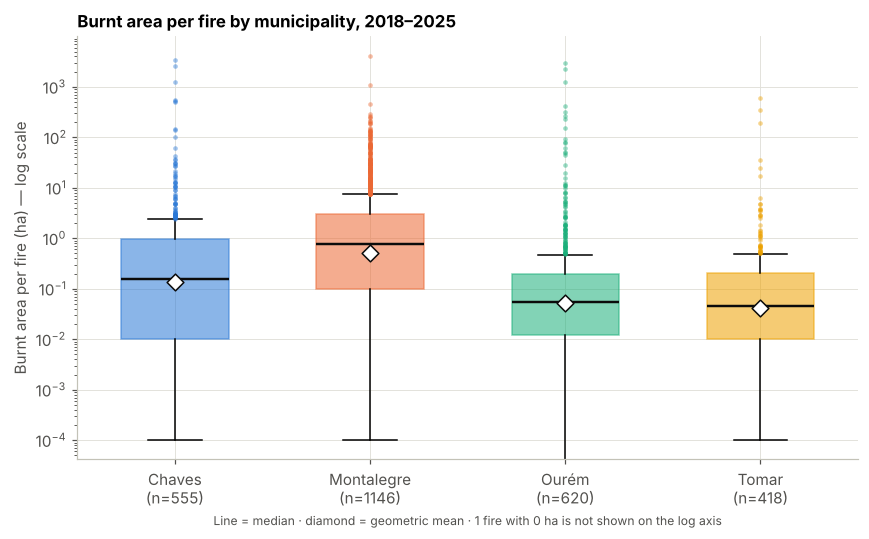

In [6]:
labels_n = [f"{m}\n(n={len(groups[m])})" for m in MUNICIPALITIES]
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot([groups[m] for m in MUNICIPALITIES], patch_artist=True, widths=0.55,
                flierprops=dict(marker="o", markersize=3, alpha=.45, markeredgewidth=0),
                medianprops=dict(color="#0b0b0b", linewidth=1.6))
for patch, fl, m in zip(bp["boxes"], bp["fliers"], MUNICIPALITIES):
    patch.set(facecolor=COLORS[m], alpha=.55, edgecolor=COLORS[m]); fl.set(markerfacecolor=COLORS[m], markeredgecolor=COLORS[m])
ax.scatter(range(1, 5), [np.exp(ln_groups[m].mean()) for m in MUNICIPALITIES], marker="D", s=60,
           facecolor="white", edgecolor="#0b0b0b", zorder=4)
ax.set_xticks(range(1, 5)); ax.set_xticklabels(labels_n)
ax.set_yscale("log"); ax.set_ylabel("Burnt area per fire (ha) — log scale")
ax.set_title("Burnt area per fire by municipality, 2018–2025")
ax.set_xlabel(f"Line = median · diamond = geometric mean · {int((q4[Y] == 0).sum())} fire with 0 ha is not shown on the log axis", fontsize=8)
plt.tight_layout(); plt.show()

### Figure 2 — How much do a few fires and a few years matter?

(a) Fires sorted from largest to smallest; the curve gives the cumulative share of total burnt area. (b) Total burnt area (hectares, original scale) by year and municipality.

Ano
2018     0.9
2019     5.2
2020    11.2
2021     6.2
2022    41.2
2023     5.6
2024     6.1
2025    23.6
Largest 1 % of fires hold 71.2 % of the total area ( 28 fires )


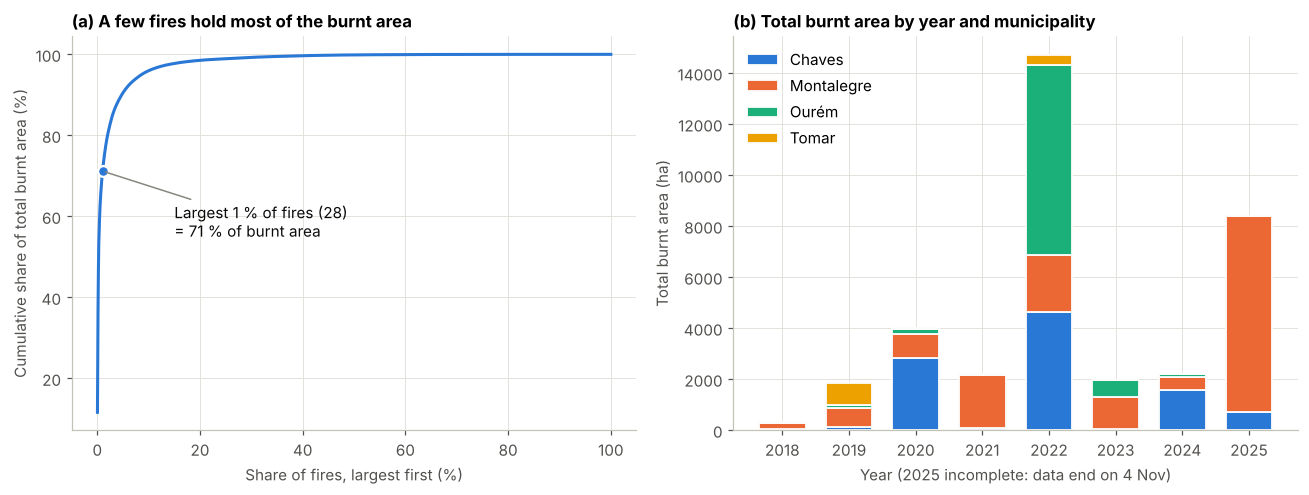

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

ax = axes[0]
a = np.sort(q4[Y].to_numpy())[::-1]
share_fires = np.arange(1, len(a) + 1) / len(a); share_area = np.cumsum(a) / a.sum()
ax.plot(100 * share_fires, 100 * share_area, color="#2a78d6", linewidth=2)
k_top = int(np.ceil(0.01 * len(a)))
ax.scatter([100 * k_top / len(a)], [100 * share_area[k_top - 1]], color="#2a78d6", s=50, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.annotate(f"Largest 1 % of fires ({k_top})\n= {100 * share_area[k_top - 1]:.0f} % of burnt area", xy=(100 * k_top / len(a), 100 * share_area[k_top - 1]),
            xytext=(15, 55), arrowprops=dict(arrowstyle="-", color="#898781"), color="#0b0b0b")
ax.set_xlabel("Share of fires, largest first (%)"); ax.set_ylabel("Cumulative share of total burnt area (%)")
ax.set_title("(a) A few fires hold most of the burnt area")

ax = axes[1]
by_year = q4.pivot_table(index="Ano", columns="Concelho", values=Y, aggfunc="sum", observed=True)[MUNICIPALITIES]
bottom = np.zeros(len(by_year))
for m in MUNICIPALITIES:
    ax.bar(by_year.index, by_year[m], bottom=bottom, color=COLORS[m], label=m, edgecolor="#fcfcfb", linewidth=1.2, width=.7)
    bottom += by_year[m].to_numpy()
ax.set_ylabel("Total burnt area (ha)"); ax.set_xlabel("Year (2025 incomplete: data end on 4 Nov)")
ax.set_title("(b) Total burnt area by year and municipality"); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

yr = by_year.sum(axis=1)
print((100 * yr / yr.sum()).round(1).rename("% of total burnt area").to_string())
print("Largest 1 % of fires hold", round(100 * share_area[k_top - 1], 1), "% of the total area (", k_top, "fires )")

### Interpretation of the EDA (descriptive only)

- **Many small fires, a few giant ones.** 77.7 % of fires burn less than 1 ha, yet the 28 largest (1 %) account for 71.2 % of the burnt area. The overall arithmetic mean (13.0 ha) is about 80 times the median (0.16 ha).
- **Arithmetic mean, median and geometric mean rank the municipalities differently.** By arithmetic mean: Chaves (18.1) > Ourém (13.9) > Montalegre (13.7) > Tomar (3.2 ha). By median and by geometric mean: Montalegre > Chaves > Ourém > Tomar (geometric means ≈ 0.50, 0.14, 0.05 and 0.04 ha). The arithmetic means are driven by a handful of huge fires: the five largest fires hold 83 % (Chaves), 84 % (Ourém), 91 % (Tomar) and 40 % (Montalegre) of the area of each municipality.
- **A few years dominate:** 2022 holds 41.2 % and 2025 (incomplete) 23.6 % of the burnt area.
- **Spread.** On the original scale the sample variances differ by a factor of 29 between municipalities.
- No negative or missing areas were found, and the largest fires are internally consistent records.

## 04 — ANOVA Assumptions

The classical one-way ANOVA model is yᵢⱼ = μᵢ + εᵢⱼ, where the errors εᵢⱼ are assumed to be **(1) independent**, **(2) normal** and **(3) of equal variance** in all groups. A **residual** is what is left after removing the group mean (eᵢⱼ = yᵢⱼ − ȳᵢ), so assumptions 2 and 3 are checked on residuals. In this section we check them on the **original scale (hectares)**; Section 05 repeats the checks on the log scale.

### 04.1 Independence

Independence means that knowing the burnt area of one fire tells us nothing about another. It is a property of how the data were generated and **cannot be proved by a statistical test**. We only look for *indications of possible clustering*; these are not proof of dependence (several fires on the same day in the same municipality may be unrelated events, and a fire near an earlier one may or may not be its continuation).

In [8]:
d_ = q4.assign(Date_only=q4["DataHoraAlerta"].dt.date)
per_day = d_.groupby(["Concelho", "Date_only"], observed=True)["Codigo_SGIF"].transform("size")
print(f"(a) Fires on a day with >= 2 fires in the same municipality: {(per_day >= 2).sum()} ({100 * (per_day >= 2).mean():.1f} %)")
print(f"(b) Reignition records: {len(rk)} ({100 * len(rk) / len(q4):.1f} %); {linked} of them follow another fire in the same parish within 3 days (heuristic)")

ly = q4_ln["ln_area"]; ss_total = ((ly - ly.mean()) ** 2).sum()
eta_year = sum(len(x) * (x.mean() - ly.mean()) ** 2 for _, x in ly.groupby(q4_ln["Ano"])) / ss_total
eta_mun = sum(len(x) * (x.mean() - ly.mean()) ** 2 for _, x in ly.groupby(q4_ln["Concelho"], observed=True)) / ss_total
print(f"(c) Share of the variance of ln(area) associated with year: {eta_year:.3f}; with municipality: {eta_mun:.3f}")

(a) Fires on a day with >= 2 fires in the same municipality: 1513 (55.2 %)
(b) Reignition records: 130 (4.7 %); 90 of them follow another fire in the same parish within 3 days (heuristic)
(c) Share of the variance of ln(area) associated with year: 0.019; with municipality: 0.134


### 04.2 Normality of the residuals

A **Q-Q plot** shows each residual against the value it would have if the data were perfectly normal: points on the line mean normality, bent tails mean skewness or heavy tails. **Skewness** (0 = symmetric) and **excess kurtosis** (0 = normal tails) summarise the shape. The **Shapiro-Wilk test** (H₀: normal) is a complement only: in large samples it rejects even harmless departures, so the plots and the size of the departure matter more than the p-value.

                    n  skewness  excess kurtosis  Shapiro W  Shapiro p
Chaves            555     14.58            227.2    0.06717  1.624e-45
Montalegre       1146     28.66            894.1    0.06045  2.247e-59
Ourém             620     15.42              252     0.0601   1.42e-47
Tomar             418     14.38            221.3    0.06178  7.085e-41
Pooled residuals 2739     20.98              493    0.06671  7.273e-79


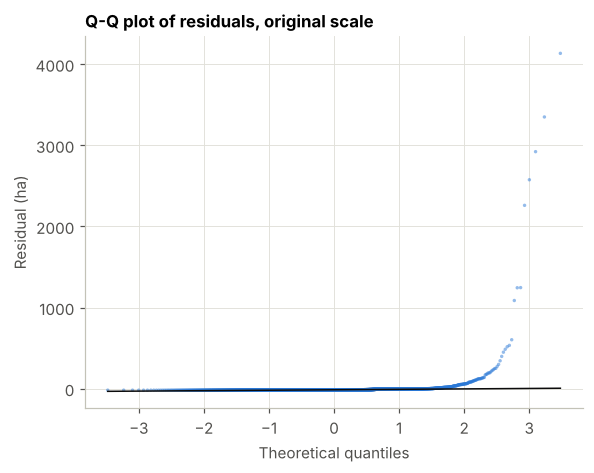

In [9]:
resid_raw = np.concatenate([groups[m] - groups[m].mean() for m in MUNICIPALITIES])
fig, ax = plt.subplots(figsize=(5.5, 4.4))
qq_panel(ax, resid_raw, "#2a78d6", "Q-Q plot of residuals, original scale", ylabel="Residual (ha)")
plt.tight_layout(); plt.show()

rows = {}
for m in MUNICIPALITIES:
    a = groups[m]; sw = stats.shapiro(a)
    rows[m] = {"n": len(a), "skewness": stats.skew(a), "excess kurtosis": stats.kurtosis(a), "Shapiro W": sw.statistic, "Shapiro p": sw.pvalue}
sw_all = stats.shapiro(resid_raw)
rows["Pooled residuals"] = {"n": len(resid_raw), "skewness": stats.skew(resid_raw), "excess kurtosis": stats.kurtosis(resid_raw),
                            "Shapiro W": sw_all.statistic, "Shapiro p": sw_all.pvalue}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.4g}"))

### 04.3 Homogeneity of variances

**Levene's test** (H₀: equal variances) compares how far observations are from their group centre; **Brown-Forsythe** is the version centred on the median, more robust to skewness. A non-significant result would not prove equal variances, and with thousands of observations a significant one can flag small differences, so the **ratio of variances** is also reported.

In [10]:
var_tab = pd.DataFrame({"n": {m: len(groups[m]) for m in MUNICIPALITIES}, "variance": {m: groups[m].var(ddof=1) for m in MUNICIPALITIES},
                        "sd": {m: groups[m].std(ddof=1) for m in MUNICIPALITIES}})
print(var_tab.round(1).to_string())
print(f"Variance ratio (max/min): {var_tab['variance'].max() / var_tab['variance'].min():.1f}")
lev_mean = stats.levene(*groups.values(), center="mean"); lev_med = stats.levene(*groups.values(), center="median")
print(f"Levene (centre = mean)           : W = {lev_mean.statistic:.3f}, p = {lev_mean.pvalue:.4g}")
print(f"Brown-Forsythe (centre = median) : W = {lev_med.statistic:.3f}, p = {lev_med.pvalue:.4g}")

               n  variance     sd
Chaves       555   36814.4  191.9
Montalegre  1146   16911.9  130.0
Ourém        620   25371.7  159.3
Tomar        418    1259.2   35.5
Variance ratio (max/min): 29.2
Levene (centre = mean)           : W = 3.177, p = 0.02315
Brown-Forsythe (centre = median) : W = 0.906, p = 0.4372


### 04.4 Summary of the assumptions on the original scale

| Assumption | Evidence | Verdict |
|---|---|---|
| **Independence** | Cannot be verified from observational records. Indications of *possible* clustering: 55 % of fires occur on days with ≥ 2 fires in the same municipality; 90 of the 130 reignition records follow another fire in the same parish within 3 days; year is associated with 2 % of the variance of ln(area). None of this proves dependence. | Not verifiable; reported as a limitation |
| **Normality** | Q-Q plot bends sharply; skewness 21.0 and excess kurtosis 493 (pooled residuals); Shapiro-Wilk p < 10⁻⁴⁰ in every group | **Clearly violated** |
| **Equal variances** | Variance ratio 29.2 (SD ratio 5.4); Levene (mean) p = 0.023; Brown-Forsythe p = 0.437 | **Not supported** (the two tests disagree because they emphasise different parts of the distribution) |

On the original scale the classical ANOVA is therefore not appropriate. Section 05 examines whether a transformation solves the problem.

## 05 — Transformation and Method Selection

The problem is a very long right tail. A common remedy for positive, right-skewed data is the logarithm, which turns multiplicative differences into additive ones and compresses the huge fires. Because the ANOVA would then be computed on a **new scale**, its conclusions refer to ln(area), i.e. to geometric means and ratios (Section 01).

We compare three response scales using the diagnostics above: the original area, `log(1 + area)` and the natural logarithm `ln(area)` (the latter excludes the single 0 ha fire). Note that `log(1 + x)` is almost equal to `x` for areas below 1 ha, which are 78 % of the fires, so it is expected to remove the skewness only partly.

In [11]:
def diagnostics(g, label):
    resid = np.concatenate([g[m] - g[m].mean() for m in MUNICIPALITIES]); var = np.array([g[m].var(ddof=1) for m in MUNICIPALITIES])
    return pd.Series({"n": sum(len(g[m]) for m in MUNICIPALITIES), "residual skewness": stats.skew(resid), "residual excess kurtosis": stats.kurtosis(resid),
                      "min Shapiro W (groups)": min(stats.shapiro(g[m]).statistic for m in MUNICIPALITIES),
                      "variance ratio (max/min)": var.max() / var.min(),
                      "Levene p (mean)": stats.levene(*g.values(), center="mean").pvalue,
                      "Brown-Forsythe p": stats.levene(*g.values(), center="median").pvalue}, name=label)

log1p_groups = {m: np.log1p(groups[m]) for m in MUNICIPALITIES}
diag = pd.DataFrame([diagnostics(groups, "original (ha)"), diagnostics(log1p_groups, "log(1 + area)"), diagnostics(ln_groups, "ln(area)")]).T
print(diag.to_string(float_format=lambda v: f"{v:.4g}"))

                          original (ha)  log(1 + area)  ln(area)
n                                  2739           2739      2738
residual skewness                 20.98          2.774    0.1287
residual excess kurtosis            493          9.991    0.2666
min Shapiro W (groups)           0.0601         0.3343     0.962
variance ratio (max/min)          29.24          4.443     1.316
Levene p (mean)                 0.02315      3.543e-73 0.0001075
Brown-Forsythe p                 0.4372       6.77e-44 0.0002396


### Figure 3 — Effect of the logarithmic transformation

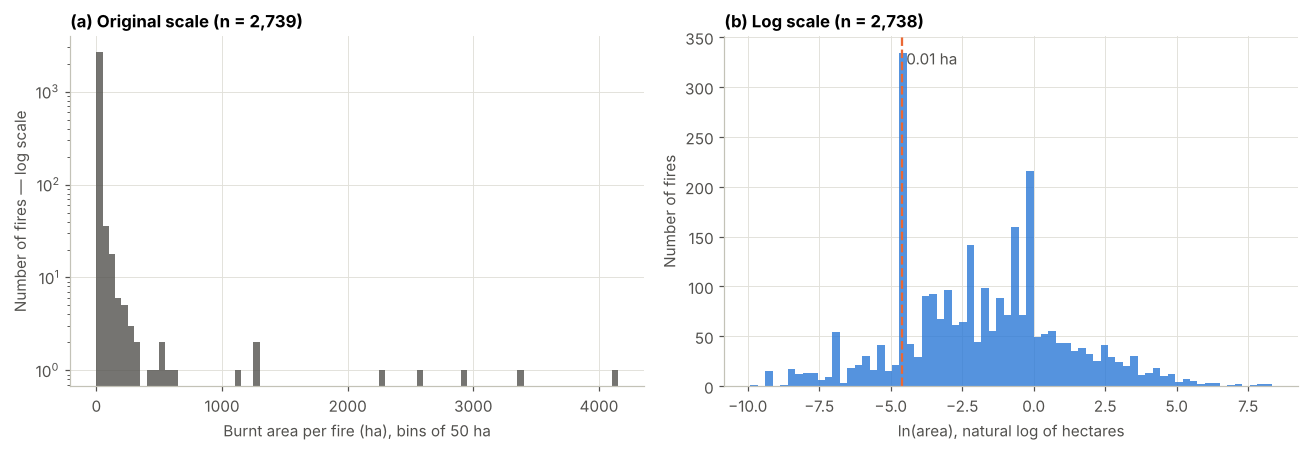

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(q4[Y], bins=np.arange(0, q4[Y].max() + 50, 50), color="#52514e", alpha=.8)
axes[0].set_yscale("log"); axes[0].set_xlabel("Burnt area per fire (ha), bins of 50 ha"); axes[0].set_ylabel("Number of fires — log scale")
axes[0].set_title("(a) Original scale (n = 2,739)")
axes[1].hist(q4_ln["ln_area"], bins=70, color="#2a78d6", alpha=.8)
axes[1].axvline(np.log(0.01), color="#eb6834", linewidth=1.5, linestyle="--")
axes[1].text(np.log(0.01) + .15, axes[1].get_ylim()[1] * .92, "0.01 ha", color="#52514e")
axes[1].set_xlabel("ln(area), natural log of hectares"); axes[1].set_ylabel("Number of fires")
axes[1].set_title("(b) Log scale (n = 2,738)")
plt.tight_layout(); plt.show()

### Residual diagnostics on the log scale

We now inspect the residuals of ln(area) both pooled and **by municipality**, together with group sizes and spreads.

              n  sd of ln(area)  skewness  excess kurtosis  Shapiro W  Shapiro p
Chaves      555           2.712    0.3838           0.2596      0.962  8.617e-11
Montalegre 1146           2.813  -0.08395          -0.4723     0.9709  2.048e-14
Ourém       619           2.712    0.4091            1.438     0.9712  1.129e-09
Tomar       418           2.452   -0.0138           0.9545     0.9765  2.697e-06
Largest/smallest SD: 1.15 | largest/smallest variance: 1.32 | largest/smallest n: 2.74


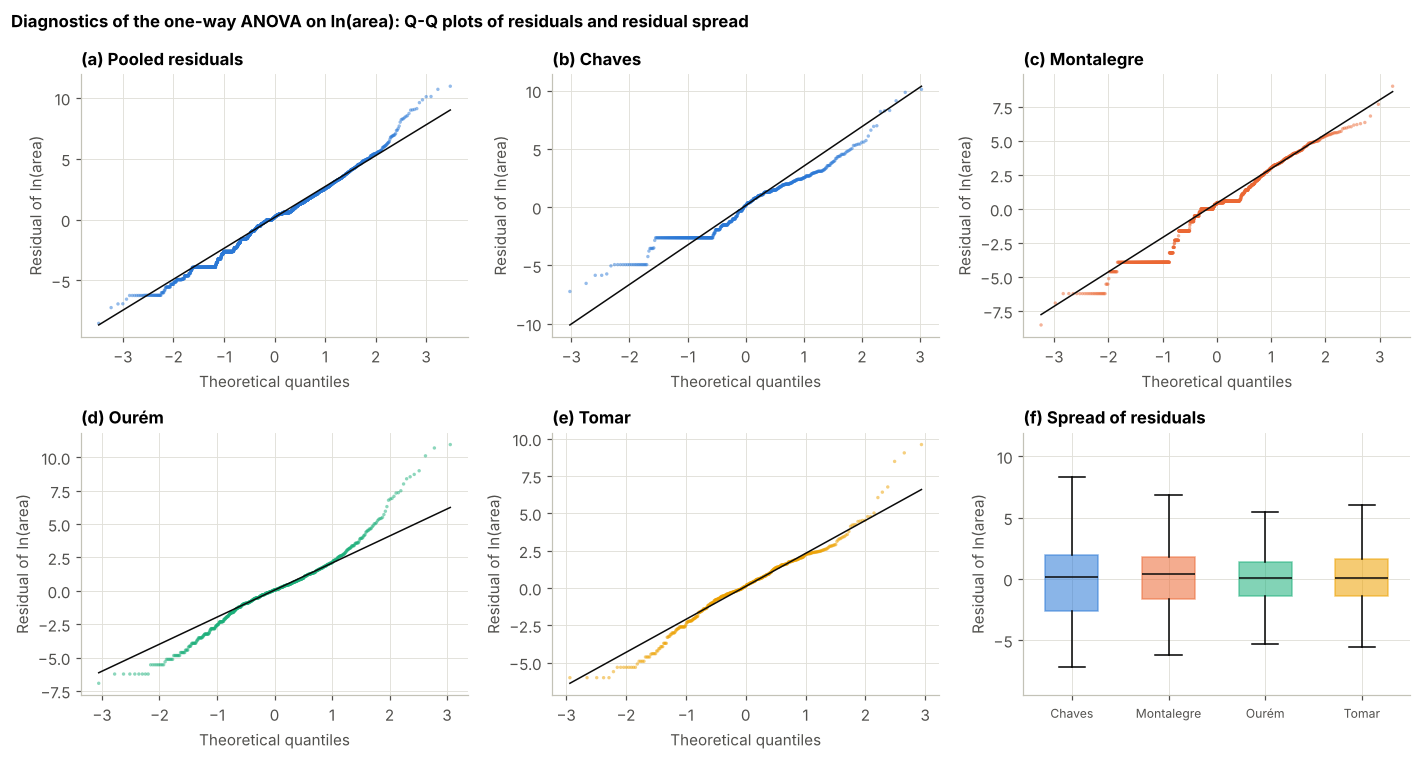

In [13]:
rows = {}
for m in MUNICIPALITIES:
    x = ln_groups[m]; sw = stats.shapiro(x)
    rows[m] = {"n": len(x), "sd of ln(area)": x.std(ddof=1), "skewness": stats.skew(x), "excess kurtosis": stats.kurtosis(x),
               "Shapiro W": sw.statistic, "Shapiro p": sw.pvalue}
ln_tab = pd.DataFrame(rows).T
print(ln_tab.to_string(float_format=lambda v: f"{v:.4g}"))
sds = ln_tab["sd of ln(area)"]
print(f"Largest/smallest SD: {sds.max() / sds.min():.2f} | largest/smallest variance: {(sds.max() / sds.min()) ** 2:.2f} | largest/smallest n: {ln_tab['n'].max() / ln_tab['n'].min():.2f}")

resid_ln = {m: ln_groups[m] - ln_groups[m].mean() for m in MUNICIPALITIES}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
qq_panel(axes[0, 0], np.concatenate(list(resid_ln.values())), "#2a78d6", "(a) Pooled residuals", ylabel="Residual of ln(area)")
for ax, m, tag in zip([axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]], MUNICIPALITIES, "bcde"):
    qq_panel(ax, resid_ln[m], COLORS[m], f"({tag}) {m}", ylabel="Residual of ln(area)")
bp = axes[1, 2].boxplot([resid_ln[m] for m in MUNICIPALITIES], patch_artist=True, widths=.55, medianprops=dict(color="#0b0b0b"),
                        flierprops=dict(marker="o", markersize=2, alpha=.4, markeredgewidth=0))
for patch, m in zip(bp["boxes"], MUNICIPALITIES):
    patch.set(facecolor=COLORS[m], alpha=.55, edgecolor=COLORS[m])
axes[1, 2].set_xticks(range(1, 5)); axes[1, 2].set_xticklabels(MUNICIPALITIES, fontsize=8)
axes[1, 2].set_title("(f) Spread of residuals"); axes[1, 2].set_ylabel("Residual of ln(area)")
fig.suptitle("Diagnostics of the one-way ANOVA on ln(area): Q-Q plots of residuals and residual spread", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

### Assessment and choice of method

| Response scale | Residual skewness | Excess kurtosis | Variance ratio | Assessment |
|---|---:|---:|---:|---|
| Original (ha) | 21.0 | 493 | 29.2 | Assumptions clearly not met |
| log(1 + area) | 2.8 | 10.0 | 4.4 | Improves, but still strongly skewed |
| **ln(area)** | **0.13** | **0.27** | **1.32** | Approximately symmetric, similar spreads |

- **Normality on the log scale.** In the centre, the Q-Q plots of the pooled residuals and of each municipality follow the reference line closely (group skewness between −0.08 and 0.41). The lower tail shows stair-steps caused by repeated recorded areas (probably rounding), and Ourém has a somewhat heavier upper tail (excess kurtosis 1.4). Shapiro-Wilk still rejects (W ≈ 0.96–0.98), as expected with 400–1,100 observations per group; the departures are moderate and much smaller than on the original scale (skewness 21, kurtosis 493).
- **Equal variances on the log scale.** The variance ratio is 1.32 (SD ratio 1.15). Levene and Brown-Forsythe remain significant (p ≈ 0.0001–0.0002), but with 2,738 observations such a small difference is detectable; it is not practically important. Because the groups with larger sizes (Montalegre, n = 1,146) also have the largest SD, the classical F-test tends to be, if anything, slightly conservative. Welch's ANOVA on the same response is nevertheless run as a sensitivity check in Section 08.
- **Remaining limits.** The concentration of recorded areas at 0.01 ha (possibly rounding or reporting conventions) creates a visible spike in Figure 3b, and independence cannot be verified (Section 04.1).
- **`log(1 + area)`** is not used because it does not remove the skewness.

**Decision.** The **primary analysis is the classical one-way ANOVA on ln(burnt area)**, with **Tukey HSD** for the pairwise comparisons. It answers the research question as formulated (differences in mean ln(area), i.e. in geometric means) and its assumptions are reasonably met. This choice was fixed from the diagnostics, before looking at any ANOVA p-value. Robustness is checked in Section 08 with Welch's ANOVA and Games-Howell on the same response, a rank-based Kruskal-Wallis test, and three alternative samples. The ANOVA does not make inferences about arithmetic means in hectares.

## 06 — One-way ANOVA (primary analysis)

**Idea.** Compare how far the municipality means are from each other (**between-group variation, SSB**) with how much the fires vary inside each municipality (**within-group variation, SSW**). Dividing each sum of squares by its degrees of freedom gives mean squares, and **F = MSB / MSW**. If H₀ were true, F would be close to 1; a large F means that the group means are further apart than the within-group noise explains. The **p-value** is the probability of an F at least this large if H₀ were true (and the assumptions held). A significant result says that *at least one* mean differs, not which one.

**Why not several t-tests?** With 4 groups there are 6 pairs; each test at α = 0.05 carries a 5 % false-positive risk, which accumulates to about 26 % across 6 tests. The ANOVA tests everything at once, and Tukey HSD controls the error rate across the pairs.

H₀: μ_Chaves = μ_Montalegre = μ_Ourém = μ_Tomar (means of ln area) · H₁: at least one differs · α = 0.05

In [14]:
# ANOVA table computed by hand (every number is traceable), then cross-checked with scipy
N_ln = len(q4_ln); n_groups = len(ln_groups)
grand = q4_ln["ln_area"].mean()
ssb = sum(len(v) * (v.mean() - grand) ** 2 for v in ln_groups.values())
ssw = sum(((v - v.mean()) ** 2).sum() for v in ln_groups.values()); sst = ssb + ssw
df_b, df_w = n_groups - 1, N_ln - n_groups
msb, msw = ssb / df_b, ssw / df_w
F = msb / msw; p_anova = stats.f.sf(F, df_b, df_w)

F_scipy, p_scipy = stats.f_oneway(*ln_groups.values())
assert np.isclose(F, F_scipy) and np.isclose(p_anova, p_scipy), "manual ANOVA differs from scipy"

anova_tab = pd.DataFrame({"SS": [ssb, ssw, sst], "df": [df_b, df_w, N_ln - 1], "MS": [msb, msw, np.nan], "F": [F, np.nan, np.nan],
                          "p-value": [p_anova, np.nan, np.nan]}, index=["Between municipalities", "Within (residual)", "Total"])
print(anova_tab.to_string(float_format=lambda v: f"{v:.5g}"))
eta2 = ssb / sst; omega2 = (ssb - df_b * msw) / (sst + msw)
print(f"F({df_b}, {df_w}) = {F:.2f}, p = {p_anova:.3g}")
print(f"Effect size on the ln scale: eta^2 = {eta2:.3f}, omega^2 = {omega2:.3f} (benchmarks: 0.01 small, 0.06 medium, 0.14 large)")

                           SS    df     MS      F    p-value
Between municipalities 3110.6     3 1036.9 140.43 1.2661e-84
Within (residual)       20187  2734 7.3836    NaN        NaN
Total                   23297  2737    NaN    NaN        NaN
F(3, 2734) = 140.43, p = 1.27e-84
Effect size on the ln scale: eta^2 = 0.134, omega^2 = 0.133 (benchmarks: 0.01 small, 0.06 medium, 0.14 large)


In [15]:
# Group estimates on the log scale and back-transformed to hectares (geometric means), with 95 % t-intervals
rows = []
for m in MUNICIPALITIES:
    v = ln_groups[m]; n = len(v); mean = v.mean(); se = v.std(ddof=1) / np.sqrt(n); t = stats.t.ppf(.975, n - 1)
    rows.append({"municipality": m, "n": n, "mean ln(area)": mean, "sd ln(area)": v.std(ddof=1), "geometric mean (ha)": np.exp(mean),
                 "95% CI low (ha)": np.exp(mean - t * se), "95% CI high (ha)": np.exp(mean + t * se)})
gm = pd.DataFrame(rows).set_index("municipality")
print(gm.round(3).to_string())

# Optional cross-check with statsmodels (runs only if the library is installed)
try:
    import statsmodels.api as sm
    from statsmodels.formula.api import ols
    fit = ols("ln_area ~ C(Concelho)", data=q4_ln.assign(Concelho=q4_ln["Concelho"].astype(str))).fit()
    tab = sm.stats.anova_lm(fit, typ=1)
    print("statsmodels F =", round(float(tab["F"].iloc[0]), 2), "| matches manual F:", bool(np.isclose(tab["F"].iloc[0], F)))
except Exception as err:
    print("statsmodels cross-check skipped:", type(err).__name__)

                 n  mean ln(area)  sd ln(area)  geometric mean (ha)  95% CI low (ha)  95% CI high (ha)
municipality                                                                                          
Chaves         555         -1.977        2.712                0.139            0.110             0.174
Montalegre    1146         -0.683        2.813                0.505            0.429             0.594
Ourém          619         -2.973        2.712                0.051            0.041             0.063
Tomar          418         -3.200        2.452                0.041            0.032             0.052
statsmodels cross-check skipped: ModuleNotFoundError


### Interpretation of the ANOVA

- **Decision.** F(3, 2734) = 140.4, p < 0.001. At α = 0.05 we **reject H₀**: there is strong evidence that the mean of ln(burnt area) is not the same in the four municipalities, i.e. that the geometric mean (typical) burnt area per fire differs between at least two of them.
- **Effect size.** η² = 0.134 (ω² = 0.133): about 13 % of the variation **of ln(burnt area)** in this model is associated with the municipality, a medium-to-large effect by conventional benchmarks. This is *not* the share of the variation of the area in hectares, and it is not a causal statement. Most of the variation (87 %) is between fires of the same municipality.
- **Geometric means** (exp of the mean of ln area, not arithmetic means and not medians): Montalegre ≈ 0.50 ha, Chaves ≈ 0.14 ha, Ourém ≈ 0.05 ha, Tomar ≈ 0.04 ha. They are close to, but not equal to, the sample medians.
- The ANOVA does not say which municipalities differ; that is the role of Section 07. The p-value assumes independent fires, which cannot be verified, so it should be read as strong but approximate evidence.

## 07 — Post-hoc Comparisons (Tukey HSD)

The ANOVA only says *whether* some mean differs. To see *which* municipalities differ we compare all 6 pairs with **Tukey HSD**, which adjusts the p-values so that the probability of **any** false positive stays at 5 % (the *family-wise error rate*). With unequal group sizes it is the Tukey-Kramer version (what `scipy.stats.tukey_hsd` computes). It is appropriate here because the primary ANOVA is the classical one on ln(area), with nearly equal variances.

The differences are in ln(area). Exponentiated, each difference is a **ratio of geometric means**: a ratio of 3 means that the typical fire in the first municipality is 3 times that of the second; a ratio of 1 means no difference. Pairs are ordered so that the municipality with the larger geometric mean comes first.

In [16]:
tk = stats.tukey_hsd(*[ln_groups[m] for m in MUNICIPALITIES])
ci_tk = tk.confidence_interval(confidence_level=0.95)
order = sorted(range(4), key=lambda i: -ln_groups[MUNICIPALITIES[i]].mean())     # larger geometric mean first
means_ln = {m: ln_groups[m].mean() for m in MUNICIPALITIES}

rows = []
for x in range(4):
    for y in range(x + 1, 4):
        i, j = order[x], order[y]                                              # i has the larger mean
        a, b = MUNICIPALITIES[i], MUNICIPALITIES[j]; d_ln = means_ln[a] - means_ln[b]
        assert np.isclose(d_ln, tk.statistic[i, j]) and np.isclose(ci_tk.low[j, i], -ci_tk.high[i, j])
        rows.append({"comparison (first / second)": f"{a} / {b}", "difference in ln(area)": d_ln, "ratio of geometric means": np.exp(d_ln),
                     "95% CI ratio low": np.exp(ci_tk.low[i, j]), "95% CI ratio high": np.exp(ci_tk.high[i, j]),
                     "Tukey adj. p": tk.pvalue[i, j], "significant (0.05)": bool(tk.pvalue[i, j] < 0.05)})
posthoc = pd.DataFrame(rows).set_index("comparison (first / second)")
shown = posthoc.copy(); shown["Tukey adj. p"] = posthoc["Tukey adj. p"].map(lambda v: "< 0.0001" if v < 1e-4 else f"{v:.4f}")
print(shown.to_string(float_format=lambda v: f"{v:.4g}"))
primary_sig = {frozenset(c.split(" / ")) for c, r in posthoc.iterrows() if r["significant (0.05)"]}
print("Significant pairs:", len(primary_sig), "of 6")

                             difference in ln(area)  ratio of geometric means  95% CI ratio low  95% CI ratio high Tukey adj. p  significant (0.05)
comparison (first / second)                                                                                                                        
Montalegre / Chaves                           1.293                     3.645              2.54              5.232     < 0.0001                True
Montalegre / Ourém                            2.289                     9.868             6.965              13.98     < 0.0001                True
Montalegre / Tomar                            2.517                     12.39              8.31              18.46     < 0.0001                True
Chaves / Ourém                               0.9958                     2.707             1.799              4.072     < 0.0001                True
Chaves / Tomar                                1.223                     3.398             2.161              5.3

### Figure 4 — Pairwise ratios of geometric means

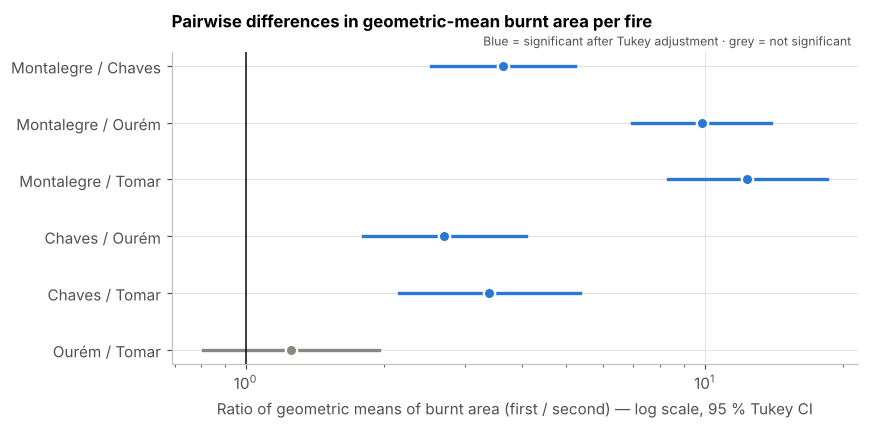

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ypos = np.arange(len(posthoc))[::-1]
for y_, (name, r) in zip(ypos, posthoc.iterrows()):
    col = "#2a78d6" if r["significant (0.05)"] else "#898781"
    ax.plot([r["95% CI ratio low"], r["95% CI ratio high"]], [y_, y_], color=col, linewidth=2.2)
    ax.scatter(r["ratio of geometric means"], y_, s=55, color=col, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.axvline(1, color="#0b0b0b", linewidth=1)
ax.set_xscale("log"); ax.set_yticks(ypos); ax.set_yticklabels(posthoc.index)
ax.set_xlabel("Ratio of geometric means of burnt area (first / second) — log scale, 95 % Tukey CI")
ax.set_title("Pairwise differences in geometric-mean burnt area per fire", pad=16)
ax.text(0.99, 1.02, "Blue = significant after Tukey adjustment · grey = not significant", transform=ax.transAxes, ha="right", fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

### Interpretation of the post-hoc comparisons

At a family-wise level of 5 %:

- **Montalegre** has a larger geometric-mean burnt area than each of the other three municipalities: about 3.6 times Chaves, 9.9 times Ourém and 12.4 times Tomar (adjusted p < 0.0001).
- **Chaves** is larger than Ourém (≈ 2.7 times) and Tomar (≈ 3.4 times) (adjusted p < 0.0001).
- **Ourém and Tomar do not differ significantly** (ratio 1.26, 95 % CI 0.81–1.95, adjusted p = 0.55). Failing to detect a difference is not evidence that they are equal; the interval is compatible with ratios from about 0.8 to 2.
- All 6 pairs were compared, and the confidence intervals are on the ratio scale (log differences exponentiated), not in hectares.
- **Statistical vs. practical importance.** The geometric means are all below 1 ha, so a ratio of 10 (e.g., 0.50 ha vs 0.05 ha) is statistically strong but small in absolute hectares; the total burnt area is determined by rare extreme fires, which the logarithm deliberately down-weights.

## 08 — Selected Robustness Checks

To see whether the conclusion depends on the choices made along the way, we repeated the analysis changing one of them at a time. We only kept the checks that are relevant to Q4, and all of them use the same response variable, ln(area):

1. **Welch's ANOVA and Games-Howell comparisons.** These do not require equal variances, so they show whether the result depends on that assumption.
2. **Kruskal-Wallis test.** It is based on ranks and is therefore unaffected by monotone transformations such as the logarithm, so it shows whether the result depends on normality. It compares distributions, not means.
3. **Excluding 2025,** which is an incomplete year.
4. **Human-related fires only** (intentional and negligent), which connects Q4 to the theme of the project.
5. **Excluding the 28 largest fires** (1 % of the sample), as an exploratory check on whether a few extreme fires drive the result.

Permutation tests were not used. Permuting the municipality labels tests the stronger hypothesis that the whole distributions are identical, which is hard to justify when the groups have different variances and shapes. Welch's ANOVA is implemented below and was validated against the Welch t-test, since for two groups F equals t².

In [18]:
def welch_anova(samples):
    # Welch (1951) one-way ANOVA for unequal variances; returns F, df1, df2, p
    n = np.array([len(x) for x in samples]); m = np.array([x.mean() for x in samples]); v = np.array([x.var(ddof=1) for x in samples])
    kk = len(samples); w = n / v; W = w.sum(); mw = (w * m).sum() / W
    A = (w * (m - mw) ** 2).sum() / (kk - 1); lam = ((1 - w / W) ** 2 / (n - 1)).sum()
    B = 1 + 2 * (kk - 2) / (kk ** 2 - 1) * lam
    Fw = A / B; df2 = (kk ** 2 - 1) / (3 * lam)
    return Fw, kk - 1, df2, stats.f.sf(Fw, kk - 1, df2)

def games_howell(samples):
    # Games-Howell adjusted p-values for all pairs (unequal variances); returns a symmetric matrix
    kk = len(samples); P = np.ones((kk, kk))
    for i in range(kk):
        for j in range(i + 1, kk):
            a, b = samples[i], samples[j]; va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
            df_ = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
            q_ = abs(a.mean() - b.mean()) / np.sqrt((va + vb) / 2)
            P[i, j] = P[j, i] = stats.studentized_range.sf(q_, kk, df_)
    return P

# Validation: with two groups, Welch's F equals the square of the Welch t statistic
t_chk = stats.ttest_ind(ln_groups["Chaves"], ln_groups["Montalegre"], equal_var=False)
F_chk, _, df_chk, _ = welch_anova([ln_groups["Chaves"], ln_groups["Montalegre"]])
assert np.isclose(F_chk, t_chk.statistic ** 2) and np.isclose(df_chk, t_chk.df), "Welch implementation check failed"

def ln_samples(df):
    dd = df[df[Y] > 0]
    return [np.log(dd.loc[dd["Concelho"] == m, Y].to_numpy()) for m in MUNICIPALITIES]

def sig_set(P):
    return {frozenset((MUNICIPALITIES[i], MUNICIPALITIES[j])) for i in range(4) for j in range(i + 1, 4) if P[i, j] < 0.05}

def pattern(sig):
    return "same pairs as primary" if sig == primary_sig else "DIFFERS: " + str(sorted(tuple(sorted(s)) for s in sig ^ primary_sig))

def classical(samples):
    F_, p_ = stats.f_oneway(*samples); allv = np.concatenate(samples); gm_ = allv.mean()
    return F_, p_, sum(len(x) * (x.mean() - gm_) ** 2 for x in samples) / ((allv - gm_) ** 2).sum()

rows = []
S_all = ln_samples(q4)
F1, p1, e1 = classical(S_all); assert np.isclose(F1, F)
rows.append({"analysis": "Primary: classical ANOVA + Tukey, all fires", "n": sum(map(len, S_all)), "statistic": f"F = {F1:.1f}", "p-value": p1, "eta^2": e1,
             "pairwise pattern": pattern(sig_set(tk.pvalue))})
Fw, d1, d2, pw = welch_anova(S_all)
rows.append({"analysis": "Welch ANOVA + Games-Howell, all fires", "n": sum(map(len, S_all)), "statistic": f"F = {Fw:.1f}", "p-value": pw, "eta^2": np.nan,
             "pairwise pattern": pattern(sig_set(games_howell(S_all)))})
H, pH = stats.kruskal(*[groups[m] for m in MUNICIPALITIES])
rows.append({"analysis": "Kruskal-Wallis (ranks), all fires", "n": len(q4), "statistic": f"H = {H:.1f}", "p-value": pH, "eta^2": np.nan, "pairwise pattern": "not applicable"})
top28 = q4.nlargest(28, Y).index
for label, df_ in [("Classical ANOVA + Tukey, excluding 2025", sample_no_2025), ("Classical ANOVA + Tukey, human-related fires only", sample_human),
                   ("Classical ANOVA + Tukey, excluding the 28 largest fires", q4.drop(top28))]:
    S = ln_samples(df_); F_, p_, e_ = classical(S)
    rows.append({"analysis": label, "n": sum(map(len, S)), "statistic": f"F = {F_:.1f}", "p-value": p_, "eta^2": e_,
                 "pairwise pattern": pattern(sig_set(stats.tukey_hsd(*S).pvalue))})

robust = pd.DataFrame(rows).set_index("analysis")
robust["p-value"] = robust["p-value"].map(lambda v: "< 0.0001" if v < 1e-4 else f"{v:.4f}")
print(robust.to_string(float_format=lambda v: f"{v:.3f}"))
print()
print(f"Welch on ln(area): F({d1}, {d2:.0f}) = {Fw:.2f}")

                                                            n  statistic   p-value  eta^2       pairwise pattern
analysis                                                                                                        
Primary: classical ANOVA + Tukey, all fires              2738  F = 140.4  < 0.0001  0.134  same pairs as primary
Welch ANOVA + Games-Howell, all fires                    2738  F = 142.8  < 0.0001    NaN  same pairs as primary
Kruskal-Wallis (ranks), all fires                        2739  H = 376.0  < 0.0001    NaN         not applicable
Classical ANOVA + Tukey, excluding 2025                  2418  F = 110.5  < 0.0001  0.121  same pairs as primary
Classical ANOVA + Tukey, human-related fires only        2484  F = 135.0  < 0.0001  0.140  same pairs as primary
Classical ANOVA + Tukey, excluding the 28 largest fires  2710  F = 154.7  < 0.0001  0.146  same pairs as primary

Welch on ln(area): F(3, 1238) = 142.82


### Interpretation of the robustness checks

- **Equal variances.** Welch's ANOVA on ln(area) leads to the same conclusion as the classical ANOVA (F(3, 1238) = 142.8, p < 0.0001), and the Games-Howell comparisons identify the same pairs as Tukey HSD. The main result therefore does not depend on the assumption of equal variances.
- **Normality.** The Kruskal-Wallis test, which is based on ranks and is not affected by the logarithmic transformation, also rejects the equality of the distributions (H = 376.0, p < 0.0001). It does not compare means, but it indicates that the conclusion does not rest on the normality assumption.
- **Incomplete 2025, human-related fires only and the 28 largest fires.** In all three cases the ANOVA remains highly significant (F between 110 and 155, p < 0.0001), the same five pairs differ, and Ourém and Tomar still cannot be distinguished. The value of η² stays between 0.12 and 0.15. The result is thus not driven by 2025, by non-human causes or by a few extreme fires; on the log scale, the largest fires have limited leverage.
- These checks concern the sensitivity of the **log-scale** conclusion only. None of them is an inference about arithmetic mean burnt areas in hectares which, as shown in Section 03, are dominated by a small number of very large fires.

In [19]:
# Numbers quoted in the conclusion, taken from the objects computed above (traceability check)
print(f"n = {len(q4)} fires; ANOVA sample n = {len(q4_ln)}")
print(f"ANOVA on ln(area): F({df_b}, {df_w}) = {F:.1f}, p = {p_anova:.2g}, eta^2 = {eta2:.3f}")
print("Geometric means (ha):", gm["geometric mean (ha)"].round(2).to_dict())
print(posthoc[["ratio of geometric means", "95% CI ratio low", "95% CI ratio high"]].round(2).to_string())
print("Ourem/Tomar adjusted p =", round(float(posthoc.loc["Ourém / Tomar", "Tukey adj. p"]), 2))
print(f"Welch on ln(area): F({d1}, {d2:.0f}) = {Fw:.1f}; Kruskal-Wallis H = {H:.1f}")

n = 2739 fires; ANOVA sample n = 2738
ANOVA on ln(area): F(3, 2734) = 140.4, p = 1.3e-84, eta^2 = 0.134
Geometric means (ha): {'Chaves': 0.14, 'Montalegre': 0.5, 'Ourém': 0.05, 'Tomar': 0.04}
                             ratio of geometric means  95% CI ratio low  95% CI ratio high
comparison (first / second)                                                               
Montalegre / Chaves                              3.65              2.54               5.23
Montalegre / Ourém                               9.87              6.96              13.98
Montalegre / Tomar                              12.39              8.31              18.46
Chaves / Ourém                                   2.71              1.80               4.07
Chaves / Tomar                                   3.40              2.16               5.34
Ourém / Tomar                                    1.26              0.81               1.95
Ourem/Tomar adjusted p = 0.55
Welch on ln(area): F(3, 1238) = 142.8; Kruskal-Wal

## 09 — Discussion and Conclusion


### Research question
Does the mean log-transformed burnt area per fire differ significantly across Chaves, Montalegre, Ourém and Tomar during 2018–2025?

### Methods
We analysed all valid wildfire records from the ICNF/SGIF database for 2018–2025 in the four municipalities (n = 2,739; Chaves 555, Montalegre 1,146, Ourém 620, Tomar 418), regardless of cause, without removing extreme observations (the largest fires are internally consistent records of real events). Descriptive statistics use the original burnt area in hectares. The response variable of the ANOVA was the natural logarithm of the final burnt area, ln(`Total_Burnt_Area`); the single fire with 0 ha, for which the logarithm is undefined, was left out of this analysis (n = 2,738). The factor was the municipality, and α = 0.05. The null hypothesis was that the population means of ln(burnt area) are equal in the four municipalities, and the alternative that at least one differs. For strictly positive areas, the mean of ln(area) corresponds to the logarithm of the geometric mean, so the analysis compares geometric means (the typical fire) and expresses differences as ratios; it does not test the equality of arithmetic mean burnt areas in hectares.

The logarithm was used because the burnt area is extremely right-skewed: 78 % of the fires burnt less than 1 ha, while the largest 1 % (28 fires) account for 71 % of the total burnt area. On the original scale the assumptions of the classical one-way ANOVA were clearly violated (residual skewness 21.0, excess kurtosis 493, ratio of the largest to the smallest variance 29.2). On the log scale the residuals were approximately symmetric (skewness 0.13, excess kurtosis 0.27) and the variances similar (ratio 1.32; standard deviations differing by 15 %), although the Shapiro-Wilk, Levene and Brown-Forsythe tests still rejected their null hypotheses, which is expected with more than 2,700 observations and corresponds to small departures. Independence of the records cannot be verified from observational data. We therefore used a classical one-way ANOVA on ln(area) as the primary analysis, followed by Tukey HSD for pairwise comparisons, and checked robustness with Welch's ANOVA and Games-Howell comparisons, the Kruskal-Wallis test, and repetitions excluding 2025 (incomplete year), keeping only human-related fires (intentional or negligent), and excluding the 28 largest fires.

### Results
Descriptively (original scale), the arithmetic mean burnt area per fire was 18.1 ha in Chaves, 13.9 ha in Ourém, 13.7 ha in Montalegre and 3.2 ha in Tomar, whereas the medians were 0.77, 0.16, 0.054 and 0.045 ha in Montalegre, Chaves, Ourém and Tomar, respectively. The arithmetic means are dominated by a few very large fires: the five largest fires of each municipality account for 83 % (Chaves), 84 % (Ourém), 91 % (Tomar) and 40 % (Montalegre) of its burnt area.

The ANOVA rejected the null hypothesis, F(3, 2734) = 140.4, p < 0.001, η² = 0.13: about 13 % of the variation of ln(burnt area) is associated with the municipality. The geometric mean burnt area was 0.50 ha in Montalegre, 0.14 ha in Chaves, 0.05 ha in Ourém and 0.04 ha in Tomar. According to Tukey HSD, the geometric mean in Montalegre was larger than in Chaves (ratio 3.6, 95 % CI 2.5–5.2), Ourém (9.9, 7.0–14.0) and Tomar (12.4, 8.3–18.5), and that of Chaves was larger than in Ourém (2.7, 1.8–4.1) and Tomar (3.4, 2.2–5.3), all with adjusted p < 0.0001. Ourém and Tomar did not differ significantly (ratio 1.26, 95 % CI 0.81–1.95, adjusted p = 0.55). The same conclusions were obtained with Welch's ANOVA (F(3, 1238) = 142.8, p < 0.0001) and Games-Howell comparisons, with the Kruskal-Wallis test (H = 376.0, p < 0.0001), and when excluding 2025, restricting to human-related fires or excluding the 28 largest fires (F between 110 and 155, p < 0.0001, the same five pairs differing in all cases).

### Conclusion
We reject the null hypothesis: the mean of the log-transformed burnt area per fire, differed significantly across the four municipalities in 2018–2025. It was largest in Montalegre, followed by Chaves, while Ourém and Tomar had the smallest values and could not be distinguished from each other. This result is stable across the robustness checks. It concerns the typical fire and should not be read as a comparison of arithmetic mean burnt areas in hectares: on that scale the descriptive ranking is different (Chaves has the highest mean) because a handful of very large fires dominate the means, and no inference about arithmetic means was made. Differences in the typical fire are also small in absolute terms (geometric means below 1 ha), whereas the total burnt area is determined by rare extreme fires.

### Limitations
This is an observational study, so the differences cannot be attributed to wildfire policies, the events of 2017 or any other cause; the municipalities differ in vegetation, terrain, weather and land use, and the comparison is unadjusted. The independence of the records cannot be verified: there are indications of possible clustering (55 % of the fires occurred on days with at least two fires in the same municipality, and most of the 130 reignition records followed another fire in the same parish within three days), but these do not prove dependence, so the p-values should be interpreted as approximate. Some deviations from normality and equal variances remain on the log scale, although they are small. One fire with 0 ha was excluded from the ANOVA, a noticeable share of the recorded areas is exactly 0.01 ha (possibly reflecting rounding or reporting conventions), 2025 is incomplete, and the post-2017 period mixes years before and after the 2021 law. Finally, Q4 alone does not answer the main research question of the project on response times and burnt areas before and after 2017.

### Random samples of different sizes 
## 1. Settings

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

# ===================== CHANGE ONLY THESE LINES =====================
df = pd.read_excel("01_dataset/processed/wildfires_processed.xlsx") ##filename 
RESPONSE = "Total_Burnt_Area"                # numeric column
GROUP = "Concelho"                           # column with the groups
GROUPS = ["Chaves", "Montalegre", "Ourém", "Tomar"]   # groups to compare; None = ALL groups
n = 30                                       # sample size
n_type = "total"                             # "total" = n rows in total | "per_group" = n rows from EACH group
seed = 42                                    
# ===================================================================

print("Columns in the file:", list(df.columns))
print("Groups in the file:", df[GROUP].dropna().unique())

## 2. Random sample + ANOVA table

Sorteia `n` linhas **sem reposição** (nenhuma linha se repete) e faz a ANOVA.

- H₀: μ₁ = μ₂ = … = μₖ (as médias populacionais são iguais em todos os grupos)
- H₁: pelo menos uma média é diferente

In [ ]:
data = df[[GROUP, RESPONSE]].dropna()               # keep only the 2 columns, without missing values
if GROUPS is not None:
    data = data[data[GROUP].isin(GROUPS)]           # keep only the chosen groups

if n_type == "total":
    sample = data.sample(n=n, random_state=seed)                    # n rows in total
else:
    sample = data.groupby(GROUP).sample(n=n, random_state=seed)     # n rows from each group

names = [name for name, _ in sample.groupby(GROUP)]
groups = [g[RESPONSE] for _, g in sample.groupby(GROUP)]
k, N = len(groups), len(sample)
if k < 2:
    raise ValueError("Only 1 group: ANOVA needs at least 2 groups. Check GROUPS.")

# ANOVA table
grand_mean = sample[RESPONSE].mean()
SSB = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)   # between groups
SSW = sum(((g - g.mean()) ** 2).sum() for g in groups)             # within groups
df_b, df_w = k - 1, N - k
MSB, MSW = SSB / df_b, SSW / df_w
F = MSB / MSW
p = 1 - stats.f.cdf(F, df_b, df_w)                                 # p-value = right tail
F_crit = stats.f.ppf(0.95, df_b, df_w)                             # reject H0 if F > F_crit

table = pd.DataFrame({"SS": [SSB, SSW, SSB + SSW], "df": [df_b, df_w, N - 1],
                      "MS": [MSB, MSW, None], "F": [F, None, None], "p-value": [p, None, None]},
                     index=["Between groups", "Within groups", "Total"])

print(f"N = {N} | rows per group: {sample[GROUP].value_counts().to_dict()}\n")
print(table.round(4).to_string())
print(f"\nF({df_b}, {df_w}) = {F:.3f} | critical F (5%) = {F_crit:.3f} | p-value = {p:.4f}")
print("Decision:", "reject H0" if p < 0.05 else "do not reject H0 (inconclusive)")

## 3. Assumptions

- **Independence:** não se testa; discute-se a partir de como os dados foram recolhidos.
- **Normality:** Shapiro p < 0.05 → rejeita-se a normalidade nesse grupo. Com grupos de ≈ 30 ou mais, a ANOVA aguenta desvios moderados (Teorema do Limite Central).
- **Equal variances:** Levene p < 0.05, ou rácio das variâncias acima de 3–4 → variâncias diferentes; a ANOVA clássica fica menos fiável.

In [ ]:
for name, g in zip(names, groups):
    shapiro_p = stats.shapiro(g).pvalue if len(g) >= 3 else float("nan")    # Shapiro needs at least 3 values
    print(f"{name}: n = {len(g)}, mean = {g.mean():.3f}, sd = {g.std():.3f}, Shapiro p = {shapiro_p:.4f}")

sds = [g.std() for g in groups]
print(f"\nLargest/smallest variance: {(max(sds) / min(sds)) ** 2:.2f}   (rule of thumb: below about 3-4)")
print(f"Levene p = {stats.levene(*groups).pvalue:.4f}   (H0: equal variances)")

## 4. Tukey HSD (only if H₀ is rejected)

Compara todos os pares de grupos, com p-values ajustados. Um par é significativo se p < 0.05 (e o intervalo de confiança não inclui o 0).

In [ ]:
res = stats.tukey_hsd(*groups)
ci = res.confidence_interval(confidence_level=0.95)

rows = []
for i in range(k):
    for j in range(i + 1, k):
        rows.append({"comparison": f"{names[i]} - {names[j]}", "mean difference": res.statistic[i, j],
                     "95% CI low": ci.low[i, j], "95% CI high": ci.high[i, j],
                     "p-value": res.pvalue[i, j], "significant (5%)": res.pvalue[i, j] < 0.05})
print(pd.DataFrame(rows).round(4).to_string(index=False))

## 5. Repeated samples: effect of the sample size

Para cada tamanho em `SIZES`, tira `N_REPEATS` amostras diferentes (sementes 0, 1, 2, …), faz a ANOVA em cada uma e conta quantas rejeitam H₀. Uma amostra só conta como *valid* se todos os grupos tiverem pelo menos 2 linhas.

**Interpretação:** com n maior, o erro-padrão diminui (∝ 1/√n), o teste tem mais **potência** e a taxa de rejeição sobe. Com n pequeno, não rejeitar H₀ é frequente e o resultado é **inconclusivo** — não prova que as médias são iguais.

In [ ]:
# ===================== CHANGE HERE =====================
SIZES = [10, 30, 60]       # sample sizes to compare
N_REPEATS = 20             # number of random samples for each size
# =========================================================

n_groups_all = data[GROUP].nunique()
results = []
for size in SIZES:
    rejections, valid, p_values = 0, 0, []
    for r in range(N_REPEATS):
        if n_type == "total":
            s = data.sample(n=size, random_state=r)
        else:
            s = data.groupby(GROUP).sample(n=size, random_state=r)
        gs = [g[RESPONSE] for _, g in s.groupby(GROUP)]
        if len(gs) < n_groups_all or min(len(g) for g in gs) < 2:
            continue                                  # a group is missing or too small: skip this sample
        F_r, p_r = stats.f_oneway(*gs)
        valid += 1; rejections += p_r < 0.05; p_values.append(p_r)
    results.append({"n": size, "samples": N_REPEATS, "valid": valid, "rejections": rejections,
                    "rejection rate (%)": round(100 * rejections / valid, 1) if valid else None,
                    "median p-value": round(float(np.median(p_values)), 4) if p_values else None})
print(pd.DataFrame(results).to_string(index=False))

## 7. Answer template (English — fill in the numbers)

**1. Terminology.** Let μ₁, …, μₖ be the population mean [response] in each [group] ([list the groups]). k = …, N = … observations (random sample of n = … rows, without replacement, from [dataset]). α = 0.05.

**2. Hypotheses.** H₀: μ₁ = μ₂ = … = μₖ (all population means are equal). H₁: at least one population mean differs.

**3. Methodology and assumptions.** One-way ANOVA (F distribution), comparing the variation between groups with the variation within groups (F = MSB / MSW, df₁ = k − 1, df₂ = N − k). Assumptions: (i) independent observations — [comment on how the data were collected]; (ii) approximately normal data in each group — Shapiro p = … (with groups of about 30 or more, the Central Limit Theorem makes the test robust to moderate departures); (iii) equal variances — Levene p = …, largest/smallest variance = ….

**4. Test statistic and p-value.** F(…, …) = …, p-value = … (critical F at 5 % = …).

**5. Conclusion in context.**
- *If p < 0.05:* "We reject H₀ at the 5 % level: there is statistical evidence that the mean [response] is not the same in all [groups]. Tukey HSD shows that [group A] and [group B] differ (adjusted p = …)."
- *If p ≥ 0.05:* "We do not reject H₀ at the 5 % level. The result is **inconclusive**: the sample does not provide enough evidence that the means differ, but this does not prove that they are equal."

**Sample size (section 5).** "With n = … the rejection rate over … random samples was …%, with n = … it was …%, and with n = … it was …%. Larger samples reduce the standard error (∝ 1/√n) and increase the power of the test, so real differences are detected more often; with small samples, non-rejections are frequent and inconclusive."

**Power (section 6, if asked).** "If the true means were …, the power of the test would be …, i.e. a probability of … of not detecting the difference (type II error)."

# 8. Study design — theory questions

As respostas dependem de **como os dados do exame foram recolhidos**. Lê a descrição do dataset no enunciado e responde a estas três perguntas antes de escrever:

| Pergunta | Se SIM | Se NÃO |
|---|---|---|
| O investigador **atribuiu** o "tratamento"/grupo às unidades, **ao acaso**? | experimental → pode haver **causalidade** | observacional → só **associação (correlação)** |
| As unidades foram **selecionadas ao acaso** da população? | pode-se **generalizar** à população | generalização **limitada** às unidades observadas |
| Os dados foram recolhidos **para este estudo**? | dados primários | dados **secundários** (registos administrativos, bases públicas…) |

Resumo (as duas perguntas são independentes):

| | Atribuição aleatória | Sem atribuição aleatória |
|---|---|---|
| **Seleção aleatória** | causal **e** generalizável | associação, generalizável |
| **Sem seleção aleatória** | causal, só para as unidades estudadas | associação, só para as unidades estudadas |

Nos datasets de exame (registos de vendas, incêndios, etc.) a resposta é quase sempre **observacional → correlação**, e a amostra aleatória é tirada **do dataset**, não da população inteira.

## 8.1 Correlation vs causal study

**Template (observational — the usual case):**
*"This is an observational study, so the results show an association (correlation), not causation. The researcher did not assign the [groups] to the [units] — e.g. a house is not randomly assigned to a neighbourhood — but only observed existing records. The groups may differ in other variables that also affect [response], such as [confounder 1] and [confounder 2] (confounding variables). Therefore a difference in mean [response] between [groups] cannot be attributed to the [group] itself."*

**Template (experimental — only if the statement says units were randomly assigned):**
*"This is an experiment: the [treatments] were randomly assigned to the [units], so the groups are comparable in the other variables, and a significant difference can be interpreted as a causal effect of the [treatment]."*

**Variável confundidora** = variável ligada **ao grupo e à resposta** ao mesmo tempo. Dá sempre 1–2 exemplos concretos do dataset (ex.: casas → tamanho, idade, qualidade; incêndios → vegetação, causa, meteorologia).

*Example (our project):* fires were not assigned to municipalities; in 2018–2025, 83 % of Montalegre's fires were pasture-management burnings, a cause absent in Ourém and Tomar — the cause of the fire is a confounder.

## 8.2 Generalization of conclusions

**Template:**
*"The conclusions can only be generalised to [population actually covered: units, place, period], because [the units/groups were not selected at random | the data come from a single source/period]. They cannot be extended to [other places, other periods, units not recorded], which may differ in [relevant characteristics]. Our random samples were drawn from the dataset, so they represent the dataset — not a wider population."*

Distingue sempre:
- **Target population** — o que queremos estudar (ex.: todas as casas vendidas na cidade).
- **Population covered by the data** — o que o dataset contém de facto (ex.: vendas registadas 2006–2010, só residenciais).
- **Sample** — as `n` linhas sorteadas do dataset (secção 2).

*Example (our project):* fires recorded in SGIF in Chaves, Montalegre, Ourém and Tomar, 2018–2025; the municipalities were chosen by the group, not at random, so the results do not extend to Portugal or to other years.

## 8.3 How the data was collected

Responde com o que o enunciado/documentação diz — **não inventes**. Pontos a cobrir:
1. **Source:** who collected the data and for what purpose (e.g. an official registry, a public database) → **secondary data** if not collected for this study.
2. **Unit of observation:** what one row is (one sale, one fire, one patient…).
3. **Coverage:** place, period, and whether it includes **all** units (census of the records) or a **sample**.
4. **Filters/cleaning:** rows removed and why (missing values, outliers, repeated units, selected groups).
5. **Our sampling:** "n = … rows drawn at random, without replacement, from the dataset (`random_state` = …)".

**Template:**
*"The data are secondary data from [source], originally collected for [purpose]. Each observation is one [unit], with [main variables]. The dataset covers [place, period] and contains [all recorded units / a sample of them]. [Filters applied]. For the analysis we drew random samples of n = … observations, without replacement, from this dataset."*

*Example (our project):* ICNF wildfire records (SGIF), files 2011–2020 and 2021–2025 combined; one row = one fire occurrence; all records for the 4 municipalities in 2018–2025 (n = 2,739).

## 8.4 Suggestions to improve data collection

Cada sugestão deve **resolver uma limitação** concreta. Escolhe 3–4:

| Limitation | Suggestion (English) |
|---|---|
| Groups/units not chosen at random | *Select the units (or the groups) at random — or use stratified random sampling — so that the results can be generalised to the target population.* |
| Confounding variables | *Record the main confounders ([examples]) and control for them, e.g. compare similar units (matching/blocking) or use a two-way ANOVA/regression.* |
| No causal conclusions possible | *Where feasible, use an experimental or quasi-experimental design (e.g. compare before/after a policy in affected vs unaffected areas).* |
| Measurement/recording problems | *Standardise how the variables are measured and recorded (same protocol and precision in all groups) and validate them.* |
| Small or unbalanced samples | *Use larger and balanced samples (similar n per group), chosen with a power analysis, to increase the power of the test.* |
| Dependent observations | *Identify repeated or linked units (same property sold twice, reignitions of the same fire) and keep one record per unit.* |
| Incomplete or old data | *Use complete and recent periods, and adjust for time effects (e.g. inflation, year of sale).* |

**Template:**
*"To obtain stronger conclusions, the data collection could be improved by (i) [suggestion], which would allow [benefit]; (ii) [suggestion], which would reduce [problem]; and (iii) [suggestion]."*